# A/B Test Analysis: Did the Ads Increase Conversions?
Business questions: (1) Was the campaign successful?
(2) How much of the success can be attributed to the ads?
Design: treatment = saw the advertisement (ad), control = saw a public service announcement (psa).
Data: Marketing A/B Testing by faviovaz (Kaggle).

In [1]:
#IMPORT DAN MUAT DATA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import (
    proportions_ztest, confint_proportions_2indep,
    proportion_confint, proportion_effectsize)
from statsmodels.stats.power import NormalIndPower

df = pd.read_csv("../data/marketing_AB.csv").drop(columns=["Unnamed: 0"])
df.columns = [c.replace(" ", "_") for c in df.columns]
df["converted"] = df["converted"].astype(int)

print(df.shape, "| missing:", int(df.isna().sum().sum()),
      "| duplicate user_id:", int(df["user_id"].duplicated().sum()))
df.head()

(588101, 6) | missing: 0 | duplicate user_id: 0


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


In [2]:
#UKURAN GRUP DAN KONVERSI
summary = df.groupby("test_group")["converted"].agg(
    users="count", conversions="sum", conversion_rate="mean")
display(summary)

n_ad, n_psa = summary.loc["ad", "users"], summary.loc["psa", "users"]
x_ad, x_psa = summary.loc["ad", "conversions"], summary.loc["psa", "conversions"]
cr_ad, cr_psa = x_ad / n_ad, x_psa / n_psa

,users,conversions,conversion_rate
test_group,,,
ad,564577,14423,0.025547
psa,23524,420,0.017854


In [3]:
#CEK KESEIMBANGAN GRUP
display(df.groupby("test_group")["total_ads"].agg(["mean", "median"]))

def balance(col):
    ct = pd.crosstab(df[col], df["test_group"])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return pd.Series({"chi2": round(chi2, 1), "p_value": p, "cramers_v": round(v, 4)})

pd.DataFrame({c: balance(c) for c in ["most_ads_day", "most_ads_hour"]}).T

,mean,median
test_group,,
ad,24.823365,13.0
psa,24.761138,12.0


,chi2,p_value,cramers_v
most_ads_day,235.6,4.849068e-48,0.0200
most_ads_hour,192.3,1.094574e-28,0.0181


In [4]:
#UJI HIPOTESIS UTAMA
z, p = proportions_ztest([x_ad, x_psa], [n_ad, n_psa])
lo, hi = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="diff")

print(f"Ad: {cr_ad:.3%} | PSA: {cr_psa:.3%}")
print(f"Absolute difference: {(cr_ad - cr_psa)*100:.2f} pp")
print(f"95% CI of difference: [{lo*100:.2f}, {hi*100:.2f}] pp")
print(f"Relative lift: {(cr_ad / cr_psa - 1)*100:.1f}%")
print(f"z = {z:.2f}, p-value = {p:.2e}")

Ad: 2.555% | PSA: 1.785%
Absolute difference: 0.77 pp
95% CI of difference: [0.59, 0.94] pp
Relative lift: 43.1%
z = 7.37, p-value = 1.71e-13


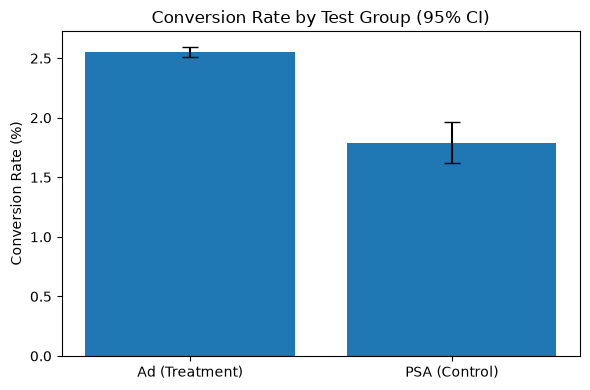

In [5]:
#GRAFIK 
fig, ax = plt.subplots(figsize=(6, 4))
rates, errs = [], []
for g in ["ad", "psa"]:
    c, n = summary.loc[g, "conversions"], summary.loc[g, "users"]
    lo_g, hi_g = proportion_confint(c, n, method="wilson")
    r = c / n
    rates.append(r * 100)
    errs.append([(r - lo_g) * 100, (hi_g - r) * 100])

ax.bar(["Ad (Treatment)", "PSA (Control)"], rates,
       yerr=np.array(errs).T, capsize=6)
ax.set_ylabel("Conversion Rate (%)")
ax.set_title("Conversion Rate by Test Group (95% CI)")
plt.tight_layout()
plt.show()

In [6]:
#POWER ANALYSIS
power = NormalIndPower()
ratio = n_ad / n_psa

effect = power.solve_power(nobs1=n_psa, alpha=0.05, power=0.8, ratio=ratio)
detectable = np.sin(np.arcsin(np.sqrt(cr_psa)) + effect / 2) ** 2
print(f"With this design, an 80%-power test can detect ~{detectable:.2%} "
      f"vs {cr_psa:.2%} (about {(detectable - cr_psa)*100:.2f} pp)")

n_equal = power.solve_power(
    effect_size=proportion_effectsize(0.02, cr_psa),
    alpha=0.05, power=0.8, ratio=1)
print(f"A 50/50 split needs ~{n_equal:,.0f} users per group to detect 1.79% -> 2.00%")

With this design, an 80%-power test can detect ~2.04% vs 1.79% (about 0.26 pp)
A 50/50 split needs ~63,250 users per group to detect 1.79% -> 2.00%


In [7]:
#BERAPA KONTRIBUSI IKLAN
incremental = (cr_ad - cr_psa) * n_ad
print(f"Estimated incremental conversions: {incremental:,.0f}")
print(f"Share of ad-group conversions attributable to ads: {incremental / x_ad:.1%}")

# Illustrative ROI: ASSUMPTIONS, replace with realistic values
AOV = 50.0   # assumed revenue per conversion
CPM = 5.0    # assumed cost per 1,000 ad impressions
ads_shown = df.loc[df["test_group"] == "ad", "total_ads"].sum()
revenue, cost = incremental * AOV, ads_shown / 1000 * CPM
print(f"Illustrative ROI: {(revenue - cost) / cost:.0%}  (AOV and CPM are assumptions)")

Estimated incremental conversions: 4,343
Share of ad-group conversions attributable to ads: 30.1%
Illustrative ROI: 210%  (AOV and CPM are assumptions)


In [8]:
#ANALISIS EKSPLORATIF PER HARI
rows = []
for day, g in df.groupby("most_ads_day"):
    a = g.loc[g["test_group"] == "ad", "converted"]
    b = g.loc[g["test_group"] == "psa", "converted"]
    _, p_day = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
    rows.append({"day": day, "cr_ad_%": a.mean() * 100, "cr_psa_%": b.mean() * 100,
                 "diff_pp": (a.mean() - b.mean()) * 100, "p_value": p_day})

by_day = pd.DataFrame(rows)
by_day["p_bonferroni"] = (by_day["p_value"] * len(by_day)).clip(upper=1)
by_day.round(4)

,day,cr_ad_%,cr_psa_%,diff_pp,p_value,p_bonferroni
0,Friday,2.2465,1.6303,0.6162,0.0116,0.0810
1,Monday,3.3241,2.2559,1.0683,0.0005,0.0036
2,Saturday,2.1307,1.3996,0.7311,0.0075,0.0524
3,Sunday,2.4620,2.0595,0.4025,0.1572,1.0000
4,Thursday,2.1637,2.0230,0.1407,0.5548,1.0000
5,Tuesday,3.0440,1.4448,1.5992,0.0000,0.0000
6,Wednesday,2.5356,1.5759,0.9597,0.0004,0.0026


## Key Findings
- The ad group converted at 2.55% vs 1.79% for the PSA control: a 0.77 pp
  absolute lift (95% CI: 0.59-0.94 pp), or 43% relative (p < 0.001).
- Roughly 30% of conversions in the ad group (~4,300) are attributable to the ads.
- The test is well powered: the observed effect is ~3x larger than the minimum
  detectable effect (~0.26 pp).
- Exploratory: lift appears strongest on Tuesdays and Mondays and absent on
  Thursdays (Bonferroni-adjusted).

## Limitations
- Group sizes are highly imbalanced (96% ad / 4% PSA); covariate balance on
  day/hour is not perfect (Cramér's V ~ 0.02).
- No revenue or cost data, so ROI is illustrative only.
- Day/hour/total_ads are measured after exposure, so segment results are exploratory.